## MNIST Digit Classification


In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf

d:\Damodarone\Python\venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


## 1. Load and inspect MNIST Dataset

In [2]:
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense
from keras.optimizers import Adam

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


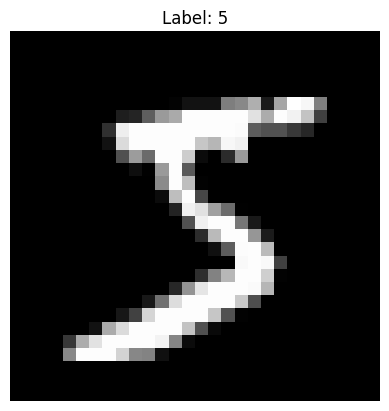

In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print('Training images:', x_train.shape)
print('Training labels:', y_train.shape)
print('Test images:', x_test.shape)
print('Test labels:', y_test.shape)

plt.imshow(x_train[0], cmap='gray')
plt.title(f'Label: {y_train[0]}')
plt.axis('off')
plt.show()


## 2. Normalize pixel values

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0


## 3. Build and compile the model

The network uses a flattened 28 × 28 image, a 128-unit ReLU hidden layer, and a 10-unit softmax output.

In [5]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the model

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=2,
    batch_size=32,
    validation_data=(x_test, y_test)
)


Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9276 - loss: 0.2562 - val_accuracy: 0.9585 - val_loss: 0.1362
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9671 - loss: 0.1102 - val_accuracy: 0.9708 - val_loss: 0.0978


## 5. Evaluate the model

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print('Test Loss:', test_loss)
print('Test Accuracy:', test_accuracy)


  1/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9688 - loss: 0.0518

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9708 - loss: 0.0978
Test Loss: 0.09783630073070526
Test Accuracy: 0.97079998254776


## 6. Plot training and validation accuracy/loss

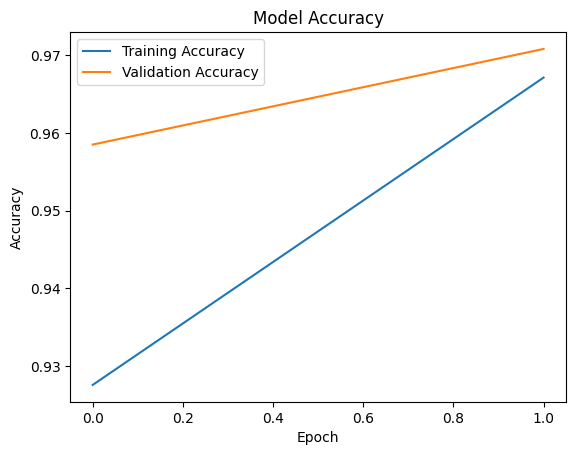

In [8]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

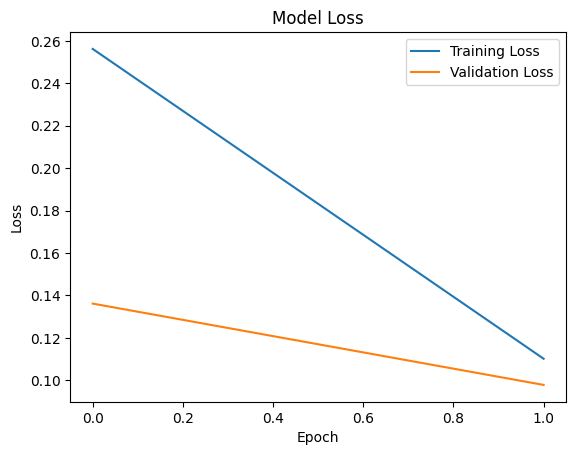

In [9]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


## 7. Predict a handwritten digit

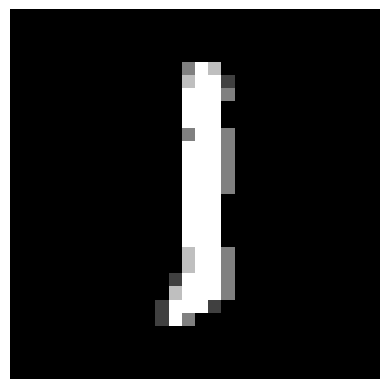

The handwritten number in the image is 1


In [10]:
n = int(input("Enter any index : "))
plt.imshow(x_test[n], cmap='gray')
plt.axis('off')
plt.show()

prediction = model.predict(x_test[n:n + 1], verbose=0)
predicted_digit = int(np.argmax(prediction[0]))
print('The handwritten number in the image is', predicted_digit)
